# Experiments 8–11 — Results and plots

This notebook is the single analysis and visualization entry point for the multi-UAV experiments. It reads the CSV files produced by the simulation-only notebooks; it never runs a simulation.


In [1]:
from __future__ import annotations

import csv
from collections import defaultdict
from pathlib import Path
from statistics import fmean

import matplotlib.pyplot as plt


## Result locations

Add or remove entries below to control which experiments are analyzed. Missing CSV files are reported and skipped.


In [2]:
EXPERIMENTS = {
    "8": {
        "title": "Experiment 8 — Nominal conditions",
        "csv": Path("outputs/output_8/replication_metrics.csv"),
        "figures": Path("figs/figs_8"),
        "geofences": False,
    },
    "9": {
        "title": "Experiment 9 — Broad wind regions",
        "csv": Path("outputs/output_9/replication_metrics.csv"),
        "figures": Path("figs/figs_9"),
        "geofences": False,
    },
    "10": {
        "title": "Experiment 10 — Dynamic geofences",
        "csv": Path("outputs/output_10/replication_metrics.csv"),
        "figures": Path("figs/figs_10"),
        "geofences": True,
    },
    "11": {
        "title": "Experiment 11 — Combined conditions",
        "csv": Path("outputs/output_11/replication_metrics.csv"),
        "figures": Path("figs/figs_11"),
        "geofences": True,
    },
}

STRATEGY_ORDER = ("sd_only", "td_only", "sd_td")
STRATEGY_LABELS = {
    "sd_only": "SD only",
    "td_only": "TD only",
    "sd_td": "SD + TD",
}
# Colors of the Brazilian flag (blue, yellow and green). Every strategy uses
# plain circular markers and a solid line, except SD + TD, which is dashed so
# that it remains distinguishable where it overlaps SD only.
COLORS = {
    "sd_only": "#FFDF00",
    "td_only": "#002776",
    "sd_td": "#009C3B",
}
OUTLINE = "#3D3D3D"
LINE_STYLES = {"sd_only": "-", "td_only": "-", "sd_td": (0, (4, 2))}
MARKERS = {"sd_only": "o", "td_only": "o", "sd_td": "o"}
REQUIRED_MINIMUM_SEPARATION = 30.0

# Figures are sized for an A4 text block (about 16 cm wide) and use a
# Times-like serif font to match the thesis body text. Titles are left to
# the LaTeX captions.
TEXT_WIDTH_IN = 6.3
ACADEMIC_STYLE = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8.5,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "savefig.facecolor": "white",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "pdf.fonttype": 42,
}


## CSV reading and summarization


In [3]:
INTEGER_COLUMNS = {"number_of_uavs", "replication", "seed"}


def read_metrics(path: str | Path) -> list[dict[str, object]]:
    """Read one replication CSV and restore its numeric values."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)

    with path.open(newline="", encoding="utf-8") as file:
        rows = list(csv.DictReader(file))

    for row in rows:
        for key, value in tuple(row.items()):
            if key == "strategy":
                continue
            if value == "":
                row[key] = None
            elif key in INTEGER_COLUMNS:
                row[key] = int(value)
            else:
                row[key] = float(value)
    for row in rows:
        row.setdefault("geofence_violations", 0.0)
    return rows


def summarize_metrics(rows: list[dict[str, object]]) -> list[dict[str, object]]:
    """Calculate one mean row per strategy and fleet size."""
    groups = defaultdict(list)
    for row in rows:
        groups[(row["strategy"], row["number_of_uavs"])].append(row)

    excluded = {"strategy", "number_of_uavs", "replication", "seed"}
    metric_names = [key for key in rows[0] if key not in excluded]
    summary = []
    for (strategy, number_of_uavs), group in sorted(groups.items()):
        means = {}
        for metric in metric_names:
            values = [float(row[metric]) for row in group if row[metric] is not None]
            means[metric] = fmean(values) if values else None
        summary.append({
            "strategy": strategy,
            "number_of_uavs": number_of_uavs,
            "replications": len(group),
            **means,
        })
    return summary


def write_summary(path: str | Path, summary: list[dict[str, object]]) -> None:
    """Store the summarized values beside the raw replication CSV."""
    path = Path(path)
    with path.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=summary[0].keys())
        writer.writeheader()
        writer.writerows(summary)


## Plot functions

Each line shows the arithmetic mean across the available replications. Figures carry no titles because the captions are written in LaTeX.


In [4]:
def _strategies(rows):
    available = {str(row["strategy"]) for row in rows}
    return [strategy for strategy in STRATEGY_ORDER if strategy in available]


def _fleet_sizes(rows):
    return sorted({int(row["number_of_uavs"]) for row in rows})


def _group_values(rows, strategy, number_of_uavs, metric):
    return [
        float(row[metric])
        for row in rows
        if row["strategy"] == strategy
        and row["number_of_uavs"] == number_of_uavs
        and row[metric] is not None
    ]


def _style_axis(axis):
    axis.grid(True, color="#D9D9D9", linewidth=0.45, linestyle=":")
    axis.set_axisbelow(True)
    axis.margins(x=0.03)


def plot_metric(axis, rows, metric, ylabel, *, lower_bound=0.0):
    """Plot the mean over replications for each strategy and fleet size."""
    fleet_sizes = _fleet_sizes(rows)
    for strategy in _strategies(rows):
        means = []
        for number_of_uavs in fleet_sizes:
            values = _group_values(rows, strategy, number_of_uavs, metric)
            means.append(fmean(values) if values else float("nan"))
        axis.plot(
            fleet_sizes,
            means,
            color=COLORS[strategy],
            linestyle=LINE_STYLES[strategy],
            marker=MARKERS[strategy],
            markersize=3.5,
            linewidth=1.2,
            label=STRATEGY_LABELS[strategy],
            zorder=3,
        )
    axis.set_xlabel("Number of UAVs, $N$")
    axis.set_ylabel(ylabel)
    axis.set_xticks(fleet_sizes)
    if lower_bound is not None:
        axis.set_ylim(bottom=lower_bound)
    _style_axis(axis)


def _label_panels(axes, titles):
    for index, (axis, title) in enumerate(zip(axes, titles)):
        axis.set_title(f"({chr(97 + index)}) {title}", loc="left", pad=4)


def _add_legend(figure, axis):
    handles, labels = axis.get_legend_handles_labels()
    figure.legend(
        handles,
        labels,
        loc="outside upper center",
        ncol=len(labels),
        frameon=False,
        handlelength=2.6,
        columnspacing=2.0,
    )


def _save_figure(figure, directory, stem):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    figure.savefig(directory / f"{stem}.pdf", bbox_inches="tight")
    figure.savefig(directory / f"{stem}.png", dpi=300, bbox_inches="tight")


SAFETY_PANELS = (
    ("loss_of_separation_events", "Loss-of-separation events",
     "Mean events per simulation"),
    ("collision_events", "Collision events", "Mean events per simulation"),
    ("minimum_pairwise_separation", "Minimum pairwise separation",
     "Mean minimum distance [m]"),
    ("geofence_violations", "Geofence-violation episodes",
     "Mean episodes per simulation"),
)
EFFICIENCY_PANELS = (
    ("average_actual_distance", "Executed distance per UAV",
     "Mean distance per completed UAV [m]"),
    ("average_actual_time", "Executed flight time per UAV",
     "Mean time per completed UAV [s]"),
)
OPERATIONAL_PANELS = (
    ("tactical_interventions", "Tactical intervention cycles",
     "Mean cycles per simulation"),
    ("modified_flights", "Modified flights", "Mean flights per simulation"),
    ("rejected_flights", "Rejected flights", "Mean flights per simulation"),
    ("completion_rate", "Flight completion rate", "Mean completed fraction"),
)


def _panel_figure(rows, panels, layout, height, directory, stem):
    figure, axes = plt.subplots(
        *layout,
        figsize=(TEXT_WIDTH_IN, height),
        layout="constrained",
        squeeze=False,
    )
    axes = list(axes.flat)
    for axis, (metric, _title, ylabel) in zip(axes, panels):
        # Counts start at zero; distances and times are auto-scaled so that
        # differences between strategies remain visible.
        lower_bound = None if metric.startswith("average_") else 0.0
        plot_metric(axis, rows, metric, ylabel, lower_bound=lower_bound)
        if metric == "minimum_pairwise_separation":
            axis.axhline(
                REQUIRED_MINIMUM_SEPARATION,
                color=OUTLINE,
                linestyle=":",
                linewidth=1.0,
                zorder=2,
            )
            axis.annotate(
                "30 m",
                xy=(1.0, REQUIRED_MINIMUM_SEPARATION),
                xycoords=("axes fraction", "data"),
                xytext=(-2, 2),
                textcoords="offset points",
                ha="right",
                va="bottom",
                fontsize=7.5,
                color=OUTLINE,
            )
        if metric == "completion_rate":
            axis.set_ylim(0.85, 1.005)
    _label_panels(axes, [title for _metric, title, _ylabel in panels])
    _add_legend(figure, axes[0])
    _save_figure(figure, directory, stem)
    return figure


def plot_experiment(rows, configuration):
    """Generate the safety, efficiency, operational and runtime figures."""
    directory = configuration["figures"]
    with plt.rc_context(ACADEMIC_STYLE):
        if configuration["geofences"]:
            safety = _panel_figure(
                rows, SAFETY_PANELS, (2, 2), 4.9, directory, "safety_metrics"
            )
        else:
            safety = _panel_figure(
                rows, SAFETY_PANELS[:3], (1, 3), 2.45, directory,
                "safety_metrics",
            )
        efficiency = _panel_figure(
            rows, EFFICIENCY_PANELS, (1, 2), 2.55, directory,
            "efficiency_metrics",
        )
        operations = _panel_figure(
            rows, OPERATIONAL_PANELS, (2, 2), 4.9, directory,
            "operational_metrics",
        )
        runtime = _panel_figure(
            rows,
            (("wall_time_seconds", "Wall-clock execution time",
              "Mean runtime per simulation [s]"),),
            (1, 1), 2.6, directory, "computational_runtime",
        )
    return safety, efficiency, operations, runtime


## Load available experiments


In [5]:
loaded_results = {}
for experiment, configuration in EXPERIMENTS.items():
    try:
        rows = read_metrics(configuration["csv"])
    except FileNotFoundError:
        print(f"{experiment}: missing {configuration['csv']}")
        continue
    loaded_results[experiment] = rows
    summary = summarize_metrics(rows)
    write_summary(configuration["csv"].with_name("mean_metrics.csv"), summary)
    print(
        f"{experiment}: {len(rows)} replications, "
        f"N={_fleet_sizes(rows)}, strategies={_strategies(rows)}"
    )


9: 24000 replications, N=[5, 10, 15, 20, 25, 30, 35, 40, 45, 50], strategies=['sd_only', 'td_only', 'sd_td']
10: 16000 replications, N=[5, 10, 15, 20, 25, 30, 35, 40, 45, 50], strategies=['sd_only', 'sd_td']
11: 16000 replications, N=[5, 10, 15, 20, 25, 30, 35, 40, 45, 50], strategies=['sd_only', 'sd_td']
12: 16000 replications, N=[5, 10, 15, 20, 25, 30, 35, 40, 45, 50], strategies=['sd_only', 'sd_td']


## Available replications ($K$) by scenario

$K$ is calculated as the number of distinct replications available for each combination of strategy and fleet size. A range is shown when some configurations are less complete than others.


In [6]:
from IPython.display import Markdown, display

k_by_scenario = {}
table_lines = [
    "| Scenario | Available $K$ per configuration | Configurations |",
    "|---|---:|---:|",
]

for experiment, rows in loaded_results.items():
    replications_by_configuration = defaultdict(set)
    for row in rows:
        key = (str(row["strategy"]), int(row["number_of_uavs"]))
        replications_by_configuration[key].add(int(row["replication"]))

    counts = {
        configuration: len(replications)
        for configuration, replications in replications_by_configuration.items()
    }
    available_k = sorted(set(counts.values()))
    if len(available_k) == 1:
        k_label = str(available_k[0])
    else:
        k_label = f"{min(available_k)}--{max(available_k)}"

    k_by_scenario[experiment] = counts
    table_lines.append(
        f"| {EXPERIMENTS[experiment]['title']} | {k_label} | {len(counts)} |"
    )

display(Markdown("\n".join(table_lines)))

for experiment, counts in k_by_scenario.items():
    unique_counts = set(counts.values())
    if len(unique_counts) > 1:
        print(f"\n{experiment}: configurations with different K values")
        for (strategy, number_of_uavs), count in sorted(counts.items()):
            print(f"  {strategy:7s} | N={number_of_uavs:3d} | K={count}")


| Scenario | Available $K$ per configuration | Configurations |
|---|---:|---:|
| Experiment 8 — Nominal conditions | 800 | 30 |
| Experiment 9 — Broad wind regions | 800 | 20 |
| Experiment 10 — Dynamic geofences | 800 | 20 |
| Experiment 11 — Combined conditions | 800 | 20 |

## Generate figures

Set `EXPERIMENTS_TO_PLOT` to a subset if only selected experiments should be regenerated.


8: saved figures in figs/figs_8
9: saved figures in figs/figs_9
10: saved figures in figs/figs_10
11: saved figures in figs/figs_11


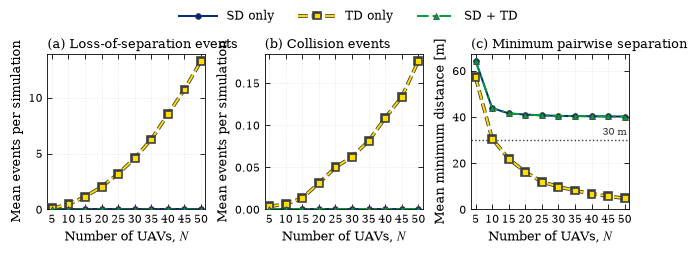

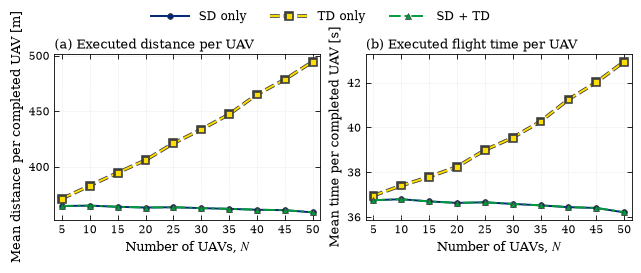

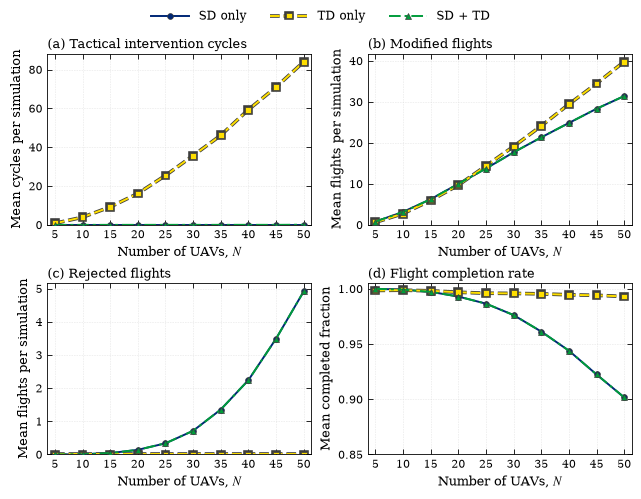

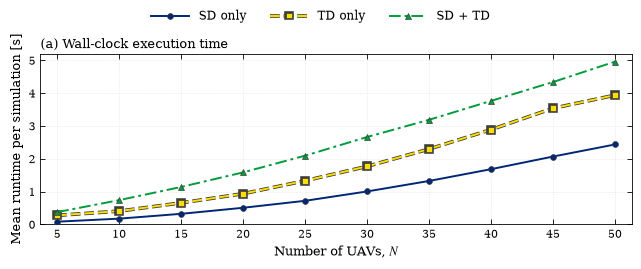

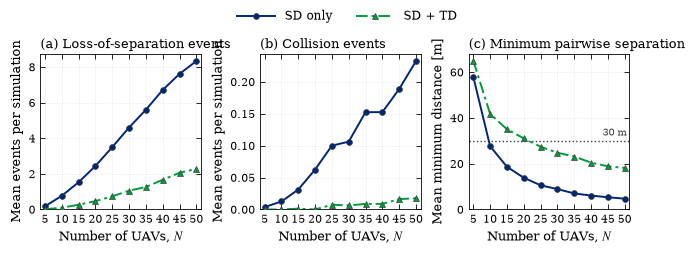

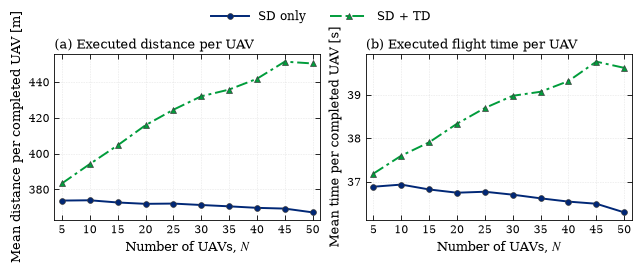

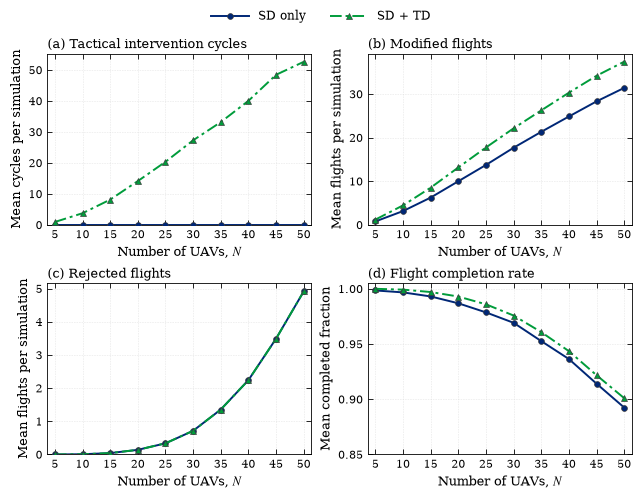

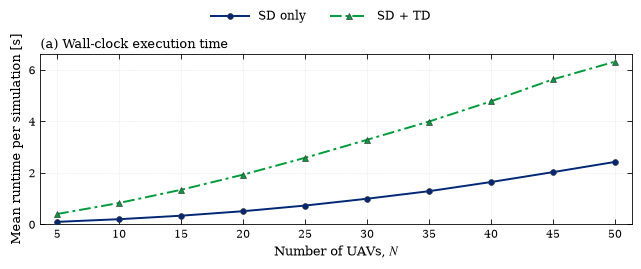

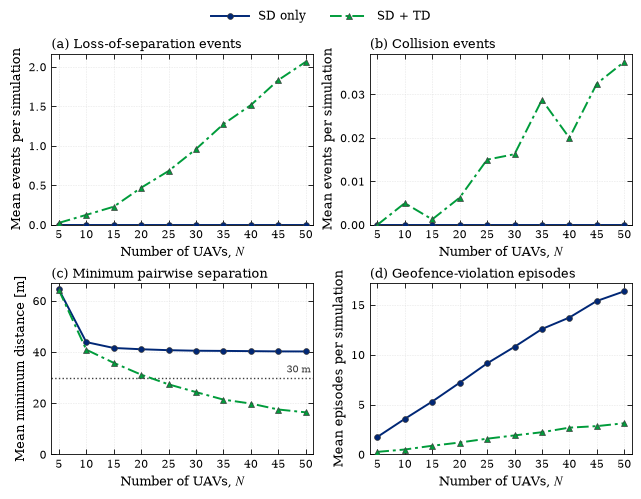

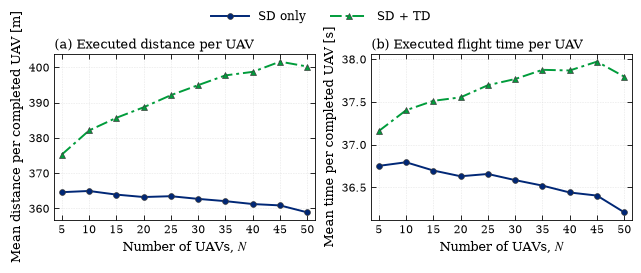

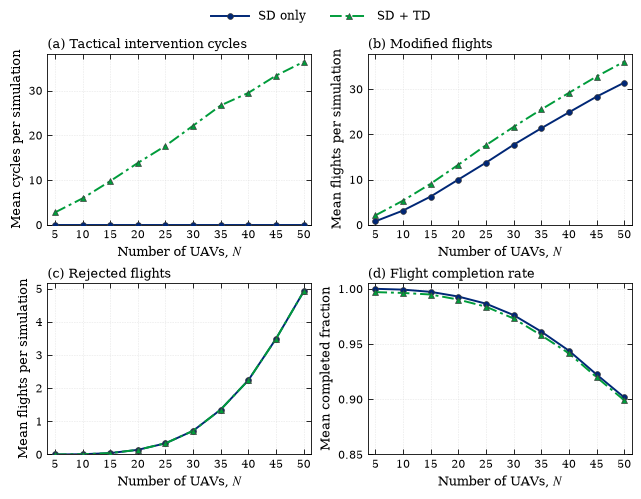

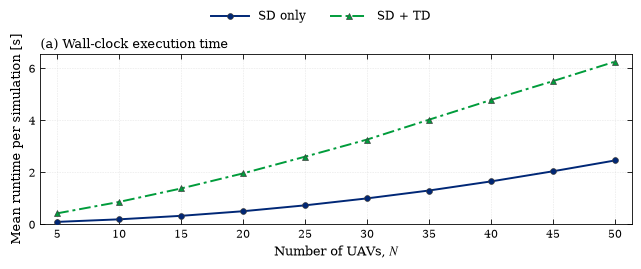

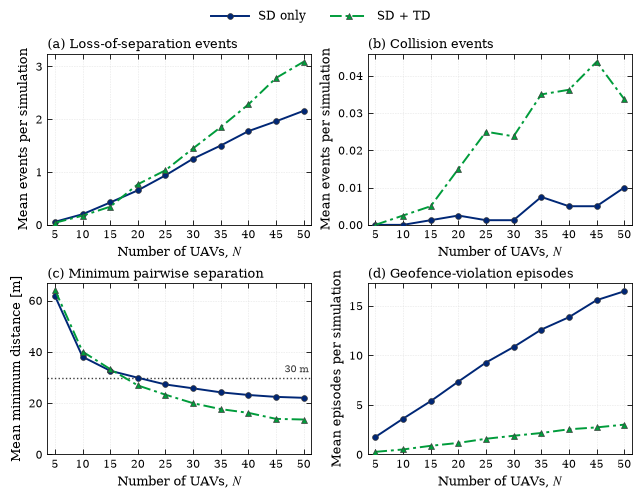

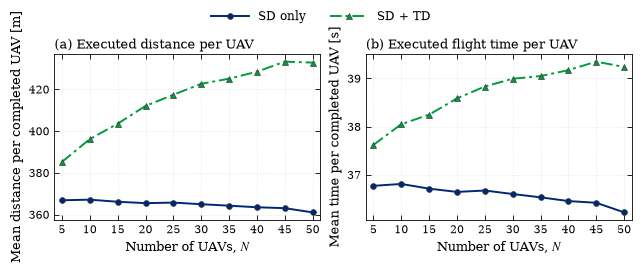

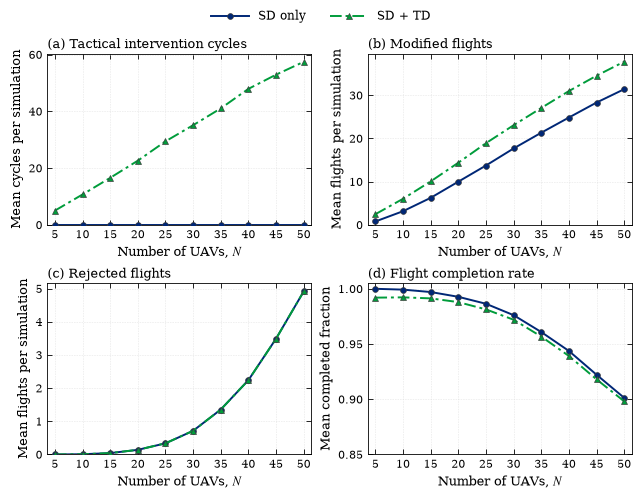

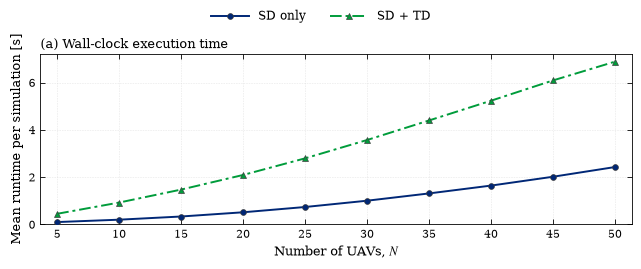

In [7]:
EXPERIMENTS_TO_PLOT = tuple(loaded_results)

figures = {}
for experiment in EXPERIMENTS_TO_PLOT:
    configuration = EXPERIMENTS[experiment]
    figures[experiment] = plot_experiment(
        loaded_results[experiment],
        configuration,
    )
    print(f"{experiment}: saved figures in {configuration['figures']}")

plt.show()


## Representative scenarios

For each experiment, the same kept replication ($N=20$, replication 1) is drawn for two strategies at $t=80$ s, when every operation has departed. Executed trajectories are solid, approved plans are dashed, and wind zones and geofences are shown when they belong to the scenario.


In [8]:
from musas.simulation import VisualizationConfig
from musas.simulation.visualization.data import load_data
from musas.simulation.visualization.rendering import draw_frame
from musas.simulation.visualization.style import academic_style_context

SNAPSHOT_N = 20
SNAPSHOT_REPLICATION = 1
SNAPSHOT_TIME = 80.0
SNAPSHOT_STRATEGIES = {
    "8": ("sd_only", "td_only"),
    "9": ("sd_only", "sd_td"),
    "10": ("sd_only", "sd_td"),
    "11": ("sd_only", "sd_td"),
}


def snapshot_config():
    return VisualizationConfig(
        view="xy",
        show_real_trajectories=True,
        show_current_positions=True,
        show_flight_plans=True,
        show_tracks=False,
        show_geofences=True,
        show_wind_zones=True,
        show_obstacles=False,
        show_legend=False,
        show_timestamp=False,
        spatial_unit="m",
    )


def plot_representative_scenario(experiment):
    """Draw one replication for two strategies side by side."""
    configuration = EXPERIMENTS[experiment]
    strategies = SNAPSHOT_STRATEGIES[experiment]
    with academic_style_context(), plt.rc_context(ACADEMIC_STYLE):
        figure, axes = plt.subplots(
            1, len(strategies),
            figsize=(TEXT_WIDTH_IN, 3.25),
            layout="constrained",
        )
        for index, (axis, strategy) in enumerate(zip(axes, strategies)):
            dataset_path = (
                configuration["csv"].parent
                / "datasets"
                / (
                    f"{strategy}_n_{SNAPSHOT_N:03d}"
                    f"_run_{SNAPSHOT_REPLICATION:02d}.sqlite"
                )
            )
            data = load_data(dataset_path, snapshot_config())
            draw_frame(axis, data, snapshot_config(), SNAPSHOT_TIME)
            axis.set_xlim(-210, 210)
            axis.set_ylim(-210, 210)
            axis.set_aspect("equal")
            axis.set_title(
                f"({chr(97 + index)}) {STRATEGY_LABELS[strategy]}",
                loc="left",
                pad=4,
            )
        _save_figure(figure, configuration["figures"], "representative_scenario")
    return figure


for experiment in SNAPSHOT_STRATEGIES:
    plot_representative_scenario(experiment)
    print("Saved:", EXPERIMENTS[experiment]["figures"] / "representative_scenario.pdf")


Saved: figs/figs_8/representative_scenario.pdf
Saved: figs/figs_9/representative_scenario.pdf
Saved: figs/figs_10/representative_scenario.pdf
Saved: figs/figs_11/representative_scenario.pdf
